In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
df =pd.read_csv("titanic.csv")

In [33]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [34]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [35]:
print(df.shape)

(891, 12)


In [36]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [38]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [39]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [40]:
df.fillna({"Age": df["Age"].median()}, inplace=True)

In [41]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [42]:
df["Embarked"].fillna(df["Embarked"].mode()[0],inplace=True)

In [43]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [44]:
df.drop("Cabin",axis=1,inplace=True)

In [45]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [46]:
df.duplicated().sum()

0

In [47]:
df.duplicated().sum()

0

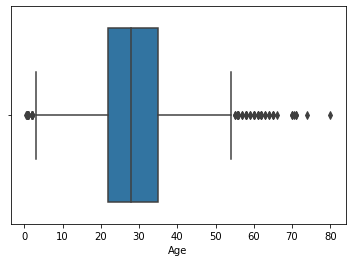

In [48]:
sns.boxplot(x=df["Age"])
plt.show()

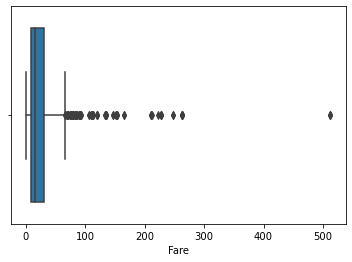

In [49]:
sns.boxplot(x=df["Fare"])
plt.show()

In [50]:
Q1=df["Fare"].quantile(0.25)
Q3=df["Fare"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
df=df[(df["Fare"] >= lower) & (df["Fare"] <=upper)]

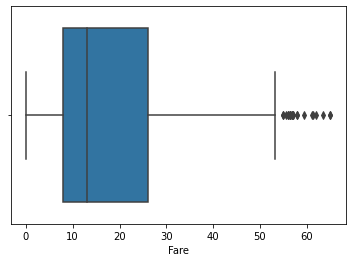

In [51]:
sns.boxplot(x=df["Fare"])
plt.show()

In [52]:
df["Sex"].unique()

array(['male', 'female'], dtype=object)

In [53]:
df["Sex"]=df["Sex"].replace("male",0)
df["Sex"]=df["Sex"].replace("female",1)

In [54]:
df["Sex"].unique()

array([0, 1], dtype=int64)

In [55]:
df["Embarked"]=df["Embarked"].replace("S",0)
df["Embarked"]=df["Embarked"].replace("C",2)
df["Embarked"]=df["Embarked"].replace("Q",1)

In [56]:
df["Embarked"].unique()

array([0, 1, 2], dtype=int64)

In [57]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0
5,6,0,3,"Moran, Mr. James",0,28.0,0,0,330877,8.4583,1


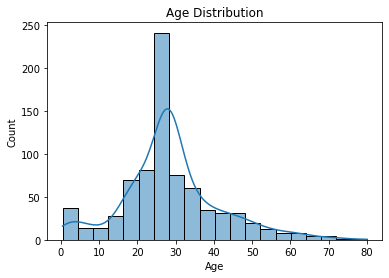

In [58]:
plt.figure(figsize=(6,4))
sns.histplot(df["Age"],bins=20,kde=True)

plt.title("Age Distribution")
plt.show()

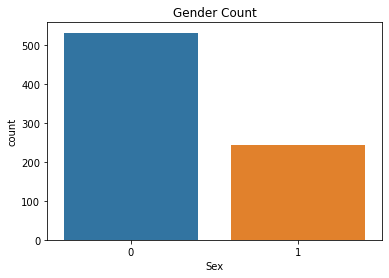

In [59]:
sns.countplot(x="Sex",data=df)
plt.title("Gender Count")
plt.show()

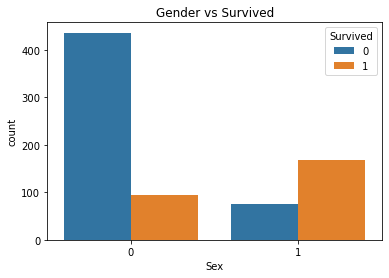

In [60]:
sns.countplot(x="Sex",hue="Survived",data=df)
plt.title("Gender vs Survived")
plt.show()

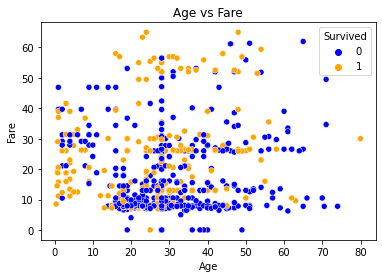

In [61]:
sns.scatterplot(
    x="Age",
    y="Fare",
    hue="Survived",
    palette=["blue", "orange"],
    data=df
)

plt.title("Age vs Fare")
plt.show()

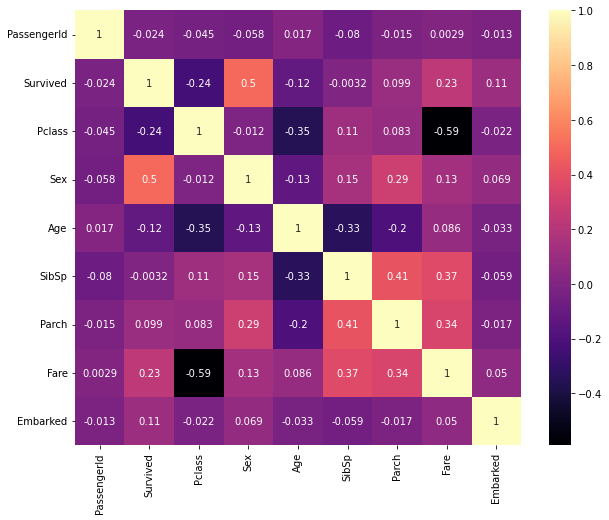

In [65]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(),
           annot=True,
           cmap='magma')

plt.show()

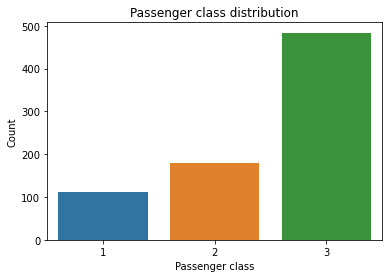

In [66]:
plt.figure(figsize=(6,4))
sns.countplot(x="Pclass",data=df)

plt.title("Passenger class distribution")
plt.xlabel("Passenger class")
plt.ylabel("Count")
plt.show()

In [67]:
X = df.drop("Survived", axis = 1)
y = df["Survived"]

In [68]:
X = X.drop(["PassengerId","Name","Ticket"], axis = 1)

In [69]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X[["Age","Fare"]] = scaler.fit_transform(X[["Age","Fare"]])

In [70]:
X.head(15)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,0,-0.528321,1,0,-0.779117,0
2,3,1,-0.215182,0,0,-0.729373,0
3,1,1,0.489381,1,0,2.599828,0
4,3,0,0.489381,0,0,-0.720161,0
5,3,0,-0.058613,0,0,-0.690071,1
6,1,0,1.976792,0,0,2.508630,0
7,3,0,-2.094017,3,1,0.239725,0
8,3,1,-0.136897,0,2,-0.492935,0
9,2,1,-1.154600,1,0,0.902677,2
10,3,1,-1.937447,1,1,-0.082693,0


In [71]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [72]:
print("Training Data :",X_train.shape)
print("Testing Data :",X_test.shape)

Training Data : (620, 7)
Testing Data : (155, 7)


In [73]:
print(X_train.head())

     Pclass  Sex       Age  SibSp  Parch      Fare  Embarked
147       3    1 -1.546024      2      2  1.219877         0
868       3    0 -0.058613      0      0 -0.613302         0
60        3    0 -0.528321      0      0 -0.780650         2
468       3    0 -0.058613      0      0 -0.744112         1
777       3    1 -1.859163      0      0 -0.394057         0
